In [1]:
from datetime import date

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

import polars as pl
import polars.selectors as cs

In [2]:
import alleg.process_data as data
import alleg.report as report

In [3]:
Stores, Inspections, Devices = (df.collect() for df in (data.Stores, data.Inspections, data.Devices))

In [82]:
PassingRate = Inspections.join(
    Devices, 'device_id',
).drop(
    '_id', cs.ends_with('_right'),
).group_by(
    pl.col('make'),
    pl.col('date').dt.truncate('1y'),
    'result',
).len().pivot(
    'result', ['Pass', 'Fail'],
    values=['len'],
).fill_null(0).with_columns(
    (pl.col('Pass')+pl.col('Fail')).alias('Total'),
    pl.col('Pass')/(pl.col('Pass')+pl.col('Fail')),
).drop('Fail').filter(pl.col('Total')>50)

In [ ]:
sns.relplot(
    Devices.filter(make='GILBARCO').select('device_id').join(Inspections, 'device_id').with_columns(
        pl.col('date').dt.truncate('1y'),
    ).to_dict(),
    x='date',
    y='result',
    kind='line',
)

In [134]:
TopMakes = Inspections.join(
    Devices, 'device_id'
).group_by('device_type','make').len().sort('len').filter(pl.col('len')>100)
TopMakes.describe()

statistic,device_type,make,len
str,str,str,f64
"""count""","""65""","""64""",65.0
"""null_count""","""0""","""1""",0.0
"""mean""",null,null,3161.276923
"""std""",null,null,10425.581347
"""min""","""DIESEL""","""AND""",101.0
"""25%""",null,null,198.0
"""50%""",null,null,399.0
"""75%""",null,null,1166.0
"""max""","""PLATFORM - PROPANE""","""ZEBRA""",64937.0


In [135]:
TopMakes.filter(pl.col('device_type')=='GASOLINE')

device_type,make,len
str,str,u64
"""GASOLINE""","""SCHLUM""",120
"""GASOLINE""","""SOUTHWEST""",178
"""GASOLINE""","""TOKHEIM""",417
"""GASOLINE""","""WAYNE""",53260
"""GASOLINE""","""GILBARCO""",64937


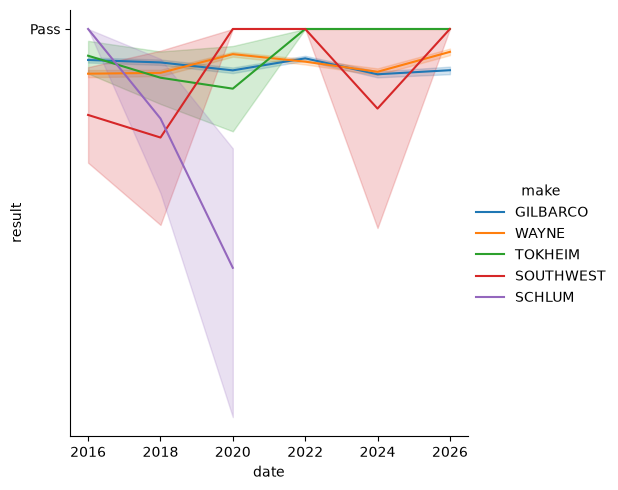

In [143]:
sns.relplot(
    TopMakes.filter(pl.col('device_type')=='GASOLINE')[['make']]
    .join(Devices, 'make')
        .select('device_id','make').join(Inspections, 'device_id').with_columns(
        pl.col('date').dt.truncate('2y'),
    ).to_dict(),
    x='date',
    y='result',
    kind='line',
    hue='make',
)

In [10]:
# Total number of inspections of a given device,
# counting all the inspections of a device on a given date only once,
DeviceInspectionCount = data.Inspections.group_by('device_id','date').agg().group_by('device_id').len()

In [11]:
DeviceInspectionCount.collect_schema()

Schema([('device_id', Int64), ('len', UInt64)])

In [21]:
data.Devices.join(
    DeviceInspectionCount, 'device_id',
).group_by('device_type','device_group','make','inspection_cycle').agg(len=pl.sum('len')).filter(
    device_type='GASOLINE',
).sort('len').collect().show(100)

device_type,device_group,make,inspection_cycle,len
str,cat,str,str,u64
"""GASOLINE""","""FUEL DISPENSER""","""FRANKLIN""","""12 MONTH""",2
"""GASOLINE""","""FUEL DISPENSER""","""GAS BOY""","""12 MONTH""",2
"""GASOLINE""","""FUEL DISPENSER""","""APS""","""12 MONTH""",4
"""GASOLINE""","""FUEL DISPENSER""","""96806""","""12 MONTH""",7
"""GASOLINE""","""FUEL DISPENSER""","""TUTHILL""","""12 MONTH""",7
"""GASOLINE""","""FUEL DISPENSER""","""FILL-RITE""","""12 MONTH""",7
"""GASOLINE""","""FUEL DISPENSER""","""AO SMITH""","""12 MONTH""",11
"""GASOLINE""","""FUEL DISPENSER""","""MARCONI""","""12 MONTH""",12
"""GASOLINE""","""FUEL DISPENSER""","""ATLAS""","""12 MONTH""",12


In [17]:
_14[['make']].show(100)

make
str
"""GAS BOY"""
"""FRANKLIN"""
"""APS"""
"""TUTHILL"""
"""FILL-RITE"""
"""96806"""
"""AO SMITH"""
"""MARCONI"""
"""ATLAS"""


In [24]:
data.Inspections.unique(['device_id','date']).with_columns(
    delay=(report.next_date-pl.col('date')).dt.total_days(),
).filter(
    pl.col('delay').is_not_null(),
).join(
    data.Devices.select('device_id','make'),
    'device_id',
).join(
    data.Devices, 'device_id',
).filter(
    pl.col('device_type') == 'GASOLINE',
    pl.col('make').is_in(["GAS BOY","FRANKLIN","APS","TUTHILL","FILL-RITE","96806"]).not_()
)

In [62]:
data.Inspections.group_by('device_id').len().collect()

device_id,len
i64,u64
19858,10
19875,10
2171,15
6610,14
12611,11
…,…
36544,1
36673,1
36674,1


In [3]:
report.Active_Inspection_Interval.sort('device_id').show(25)

inspection_id,store_id,device_id,date,result,reinspection,device_type,device_group,make,model,serial_number,pump,grade,capacity,inspection_cycle,remarks,deleted,offset,next_date,next_date_upcoming,interval,interval_upcoming
i64,i64,i64,date,cat,cat,str,cat,str,str,str,str,str,str,str,str,bool,str,date,date,duration[μs],duration[μs]
196864,33113,1,2023-08-18,"""Pass""","""Yes""","""GASOLINE""","""FUEL DISPENSER""","""GILBARCO""",null,"""406953""","""1""","""S-93""",null,"""12 MONTH""",null,false,"""12mo""",2024-05-14,2024-05-14,270d,270d
173396,33113,1,2022-07-06,"""Pass""","""Yes""","""GASOLINE""","""FUEL DISPENSER""","""GILBARCO""",null,"""406953""","""1""","""S-93""",null,"""12 MONTH""",null,false,"""12mo""",2023-07-17,2023-07-17,376d,376d
173187,33113,1,2022-06-24,"""Fail""","""No""","""GASOLINE""","""FUEL DISPENSER""","""GILBARCO""",null,"""406953""","""1""","""S-93""",null,"""12 MONTH""",null,false,"""12mo""",2022-07-06,2022-07-06,12d,12d
193008,33113,1,2023-07-17,"""Pass""","""No""","""GASOLINE""","""FUEL DISPENSER""","""GILBARCO""",null,"""406953""","""1""","""S-93""",null,"""12 MONTH""",null,false,"""12mo""",2023-08-18,2023-08-18,32d,32d
119569,33113,1,2019-06-03,"""Pass""","""No""","""GASOLINE""","""FUEL DISPENSER""","""GILBARCO""",null,"""406953""","""1""","""S-93""",null,"""12 MONTH""",null,false,"""12mo""",2020-07-15,2020-07-15,408d,408d
141657,33113,1,2020-07-15,"""Pass""","""No""","""GASOLINE""","""FUEL DISPENSER""","""GILBARCO""",null,"""406953""","""1""","""S-93""",null,"""12 MONTH""",null,false,"""12mo""",2021-05-11,2021-05-11,300d,300d
153788,33113,1,2021-05-11,"""Pass""","""No""","""GASOLINE""","""FUEL DISPENSER""","""GILBARCO""",null,"""406953""","""1""","""S-93""",null,"""12 MONTH""",null,false,"""12mo""",2022-06-24,2022-06-24,409d,409d
61501,33113,1,2016-08-18,"""Pass""","""No""","""GASOLINE""","""FUEL DISPENSER""","""GILBARCO""",null,"""406953""","""1""","""S-93""",null,"""12 MONTH""",null,false,"""12mo""",2017-03-21,2017-03-21,215d,215d
238128,33113,1,2025-08-11,"""Pass""","""No""","""GASOLINE""","""FUEL DISPENSER""","""GILBARCO""",null,"""406953""","""1""","""S-93""",null,"""12 MONTH""",null,false,"""12mo""",2026-07-22,2026-07-22,345d,345d
